# Evaluación Parcial N°1 — Machine Learning
## Caso C: Inteligencia musical y predicción de popularidad de canciones

### Integrantes
- Joaquin Muñoz
- CARLOS ALBERTO ACEVEDO CANGAS
- Jean Bizama

*El proyecto sigue la metodología CRISP-DM. Esta entrega cubre las fases de
comprensión del negocio (sección 1), comprensión de los datos (secciones 2 a 4)
y preparación de los datos (sección 5). Las fases de modelado, evaluación y
despliegue corresponden a la siguiente entrega.*

## Importacion de librerias

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA = RAIZ / "data"
IMG = RAIZ / "images"
DATA.mkdir(exist_ok=True)
IMG.mkdir(exist_ok=True)

## 1. Problema de negocio, objetivos y KPIs

### 1.1 Descripción del problema de negocio

En la industria musical se publica diariamente una gran cantidad de canciones en
las plataformas de streaming, pero no todas alcanzan el mismo nivel de popularidad.
Los sellos discográficos y las plataformas deben decidir con presupuesto limitado
qué canciones de su catálogo impulsar mediante listas editoriales y campañas de
promoción, y hoy esa selección se apoya principalmente en criterio editorial, sin
un filtro cuantitativo previo.

El problema de negocio es de priorización: identificar anticipadamente, entre miles
de canciones, cuáles presentan características asociadas a un potencial de
popularidad superior al esperable dentro de su género.

Para abordarlo se utiliza un conjunto de datos de canciones de Spotify que contiene
características musicales (energía, bailabilidad, acústica, instrumentalidad, tempo,
volumen, duración y género), además de una variable que representa su nivel de
popularidad.

### 1.2 Objetivos del proyecto

**Objetivo general**

Desarrollar un modelo de Machine Learning capaz de estimar la popularidad de
canciones de Spotify a partir de sus características musicales y su género,
aplicando análisis exploratorio, preparación de datos y en un futuro modelamiento predictivo,
para apoyar decisiones de priorización de catálogo.

**Objetivos específicos**

- Comprender y limpiar los datos: revisar tipos de dato, valores nulos, registros
  duplicados y valores inválidos, aplicando las acciones de limpieza necesarias y
  justificando cada una.
- Evaluar la calidad y las limitaciones del conjunto de datos disponible.
- Determinar si las características musicales tienen capacidad predictiva real
  sobre la popularidad, analizando su distribución y su relación con la variable
  objetivo.
- Establecer una línea base cuantitativa contra la cual medir cualquier modelo
  posterior.
- Identificar los sesgos que el uso de estos datos introduce en las decisiones de
  negocio.

### 1.3 KPIs

La variable popularity es el indicador central del proyecto. A partir de ella se
definen los siguientes KPIs:

| KPI | Definición | Cómo se mide | Meta |
|---|---|---|---|
| Precisión en priorización | % de canciones que el modelo ubica en el 10% superior de su género y que efectivamente lo están | Precision@10% por género | ≥ 40% |
| Reducción del error de estimación | Baja del error promedio respecto de predecir el promedio del género | MAE del modelo vs MAE de la línea base (9,75 puntos) | ≥ 20% de mejora |
| Cobertura del catálogo | % de canciones sobre las que el modelo puede pronunciarse | Canciones con datos válidos / catálogo total | ≥ 85% |
| Equidad entre géneros | Diferencia de error entre el género mejor y peor estimado | MAE máximo − MAE mínimo por género | ≤ 8 puntos |

### 1.4 Justificación de las metas

Las metas se derivan de líneas base calculadas sobre los propios datos, no de
supuestos.

Predecir el promedio global del catálogo da un error medio de 15,15 puntos.
Predecir el promedio del género correspondiente lo reduce a 9,75, una mejora del
35,6% sin usar ninguna característica de audio. Esa es la línea base real que
cualquier modelo debe superar, y por eso la meta del segundo KPI se fija sobre
ella y no sobre la media global.

El cuarto KPI responde a un hallazgo del análisis exploratorio: la ausencia de
datos de popularidad se concentra en géneros específicos, por lo que un modelo
podría funcionar bien en promedio y ser inservible para jazz o música latina. Un
KPI agregado ocultaría ese problema.

### 1.5 Fuentes de datos

| Atributo | Detalle |
|---|---|
| Nombre | Spotify Tracks Dataset |
| Formato | CSV |
| Volumen | 114.000 registros, 21 columnas |
| Cobertura | 114 géneros musicales, 1.000 canciones por género |
| Variable objetivo | popularity (índice 0-100 calculado por Spotify) |

Las definiciones de las características de audio (danceability, energy, valence,
etc.) provienen de la documentación oficial de la API de Spotify, que es también
el criterio usado para determinar qué valores son inválidos en la sección 3.2.

### 1.6 Herramientas utilizadas

| Herramienta | Uso en el proyecto |
|---|---|
| Google Colab | Entorno de ejecución compartido del notebook, permite trabajo simultáneo del equipo sin configurar entornos locales |
| Git/Github | Control de versiones y trabajo colaborativo |
| Python 3 | Lenguaje base del análisis |
| pandas / numpy | Manipulación, limpieza y transformación de datos |
| matplotlib / seaborn | Visualización del análisis exploratorio |

Se optó por Colab por sobre un entorno local porque el dataset supera los 20 MB y
el equipo trabaja en máquinas distintas: el notebook queda accesible para los tres
integrantes sin replicar instalaciones ni versiones de librerías.

## 2. Comprensión inicial de los datos

Antes de analizar el dataset, revisamos qué tipo de dato tiene cada columna,
cuántos valores faltan y cuántos valores distintos hay en cada una.

In [9]:
df = pd.read_csv(DATA / "Spotify_Tracks_Dataset.csv")
print(f"Filas:    {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")
df.head(3)

Filas:    114,000
Columnas: 21


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,...,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,...,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,...,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [11]:
resumen = pd.DataFrame({
    "tipo": df.dtypes,
    "nulos": df.isna().sum(),
    "unicos": df.nunique()
})
resumen

,tipo,nulos,unicos
Unnamed: 0,int64,0,114000
track_id,object,0,89741
artists,object,1,31437
album_name,object,1,46589
track_name,object,1,73608
popularity,int64,0,101
duration_ms,int64,0,50697
explicit,bool,0,2
danceability,float64,0,1174
energy,float64,0,2083


El dataset tiene 114.000 filas y 21 columnas. Solo hay 1 nulo, y está en artists, album_name y track_name a la vez (misma fila). track_id tiene 89.741 valores únicos, menos que las filas, lo que anticipa duplicados que se revisan en 3.2. Unnamed: 0 es un índice heredado sin valor analítico y se elimina.

## 3. Calidad de los datos

### 3.1 Valores nulos

Un único registro concentra todos los nulos: le faltan simultáneamente track_name,
artists y album_name. Es una fila sin identificación posible, por lo que se elimina.
No se imputa porque no hay base alguna para inventar el nombre de una canción.

### 3.2 Duplicados

El archivo tiene 114.000 filas pero menos canciones distintas.
Revisamos tres cosas: filas repetidas exactas, identificadores
repetidos y la razón detrás de esa repetición.

In [12]:
duplicados_exactos = df.drop(columns=["Unnamed: 0"]).duplicated().sum()
print(f"Filas duplicadas exactas: {duplicados_exactos}")

Filas duplicadas exactas: 450


In [13]:
print(f"Filas totales:      {df.shape[0]}")
print(f"Canciones únicas:   {df['track_id'].nunique()}")
print(f"track_id repetidos: {df['track_id'].duplicated().sum()}")

Filas totales:      114000
Canciones únicas:   89741
track_id repetidos: 24259


89.741 canciones únicas en 114.000 filas. Sobran más de 24.000

El dataset probablemente se armó consultando la API de Spotify género por género, 1.000 canciones por cada uno de los 114 géneros. Si una canción está catalogada en varios géneros, aparece varias veces, generandonos este problema.

In [14]:
generos_por_cancion = df.groupby("track_id")["track_genre"].nunique()

print(generos_por_cancion.value_counts().sort_index())
print()
print(f"Canciones en más de un género: {(generos_por_cancion > 1).sum()}")
print(f"Máximo de géneros por canción: {generos_por_cancion.max()}")

track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64

Canciones en más de un género: 16299
Máximo de géneros por canción: 9


16.299 canciones aparecen repetidas, y el caso extremo llega a 9 géneros.

In [15]:
variantes = df.groupby("track_id")["popularity"].nunique()
print(f"Canciones con popularity distinta entre sus filas: {(variantes > 1).sum()}")

Canciones con popularity distinta entre sus filas: 720


720 canciones tienen popularidad contradictoria consigo mismas. Como el dataset
no trae fecha, eso indica que la descarga se hizo por lotes en momentos distintos. Se declara como limitación.

Aparte de eso, los track_id repetidos obligan a deduplicar: si no se hace, una misma canción puede quedar en entrenamiento y en prueba al mismo tiempo, provocando fuga de datos y métricas mejores de lo que realmente son.

**Un segundo nivel de duplicados: misma canción con distinto track_id.** Además de los track_id
repetidos, una misma canción puede tener identificadores distintos (reediciones, versiones de álbum o
compilados). Esas copias también pueden filtrarse entre entrenamiento y prueba, así que se miden aparte:

In [16]:
unicos = df.drop_duplicates("track_id")
dup_contenido = unicos.duplicated(subset=["track_name", "artists", "duration_ms"]).sum()
print(f"Misma canción (nombre, artista, duración) con distinto track_id: {dup_contenido:,}")

Misma canción (nombre, artista, duración) con distinto track_id: 6,666


Hay **6.666 canciones repetidas por contenido** aunque su track_id sea distinto. No se eliminan en
esta entrega (podrían ser versiones legítimas con popularidad propia), pero sí se **marcan** en la
preparación con la columna id_contenido, para que el modelado de la siguiente entrega pueda separar
entrenamiento y prueba por grupo (GroupKFold) y evitar la fuga de datos.

### 3.3 Valores imposibles

Revisamos si hay valores que no pueden existir según la documentación de la API de Spotify: tempo o duración en cero, compases fuera de rango.

Son fallos puntuales de medición de la API, con un volumen marginal. Se eliminan
en la preparación de datos sin mayor discusión: un tempo de 0 BPM o una duración
de 0 ms no pueden existir.

In [17]:
print(f"duration_ms = 0:        {(df['duration_ms'] == 0).sum()}")
print(f"tempo = 0:              {(df['tempo'] == 0).sum()}")
print(f"time_signature inválido: {(~df['time_signature'].between(3, 7)).sum()}")

duration_ms = 0:        1
tempo = 0:              157
time_signature inválido: 1136


### 3.4 El valor cero en popularity

popularity es la variable objetivo del proyecto. Revisamos su distribución
antes de asumir que los ceros representan canciones impopulares.

In [18]:
ceros = (df["popularity"] == 0).sum()
print(f"Canciones con popularity = 0: {ceros} ({ceros / len(df) * 100:.1f}%)")
print()
print(df["popularity"].describe().round(2))

Canciones con popularity = 0: 16020 (14.1%)

count    114000.00
mean         33.24
std          22.31
min           0.00
25%          17.00
50%          35.00
75%          50.00
max         100.00
Name: popularity, dtype: float64


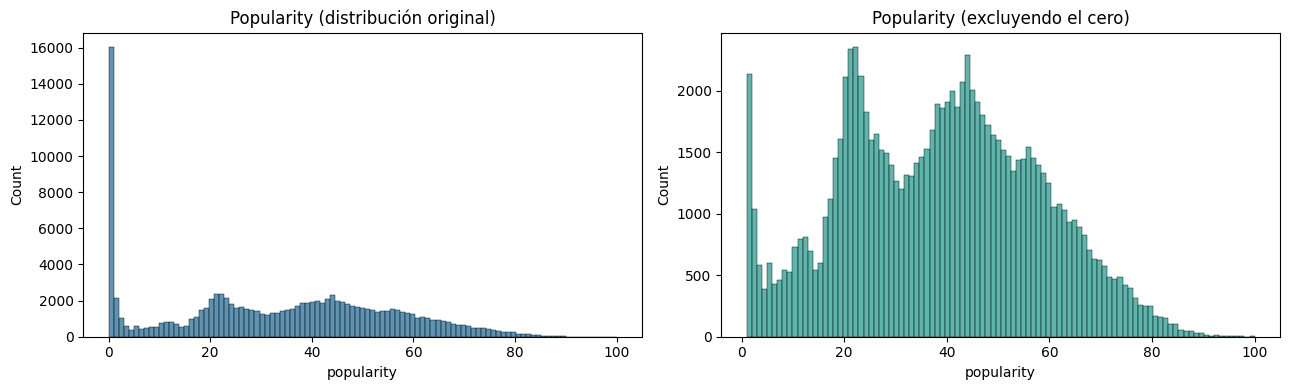

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["popularity"], bins=101, ax=axes[0], color="#2a6f97")
axes[0].set_title("Popularity (distribución original)")

sns.histplot(df[df["popularity"] > 0]["popularity"], bins=100, ax=axes[1], color="#2a9d8f")
axes[1].set_title("Popularity (excluyendo el cero)")

plt.tight_layout()
plt.show()

Si el cero representara canciones que realmente nadie escucha, debería
aparecer repartido entre todos los géneros.

In [20]:
tasa_ceros = (
    df.assign(es_cero=df["popularity"] == 0)
      .groupby("track_genre")["es_cero"]
      .mean()
      .sort_values(ascending=False) * 100
)

print(f"Géneros sin ningún cero: {(tasa_ceros == 0).sum()} de 114")
print()
print(tasa_ceros.head(10).round(1))

Géneros sin ningún cero: 3 de 114

track_genre
jazz           68.1
iranian        65.6
romance        63.6
soul           61.1
latin          58.8
country        58.7
rock           52.5
dance          49.0
alternative    48.5
house          40.3
Name: es_cero, dtype: float64


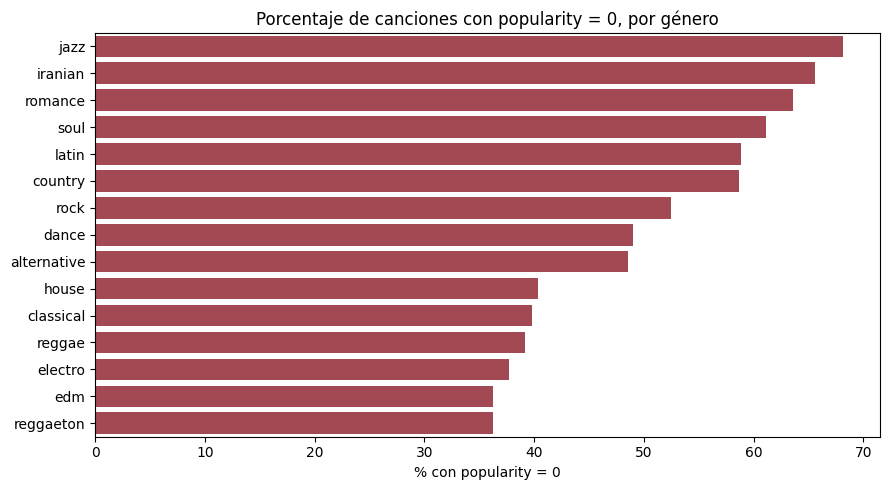

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=tasa_ceros.head(15).values, y=tasa_ceros.head(15).index,
            color="#b23a48", ax=ax)
ax.set_title("Porcentaje de canciones con popularity = 0, por género")
ax.set_xlabel("% con popularity = 0")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

La concentración de ceros descarta que representen impopularidad real: el jazz
supera el 68% mientras tres géneros no tienen ninguno. El cero es un valor que nos indica un dato faltante.

Esto convierte una decisión técnica en una decisión con consecuencias éticas,
porque las dos salidas posibles introducen sesgo:

- Eliminar esas filas descarta desproporcionadamente jazz, música latina e iraní, y el modelo resultante será menos válido para esos repertorios.
- Imputar un valor inventa una popularidad que nunca fue observada, contaminando
justamente la variable que se quiere predecir.

Se opta por excluirlas del dataset final y declarar esto como una restriccion: el modelo predice popularidad para el repertorio que Spotify sí mide,
no para todo el catálogo musical. No se imputa con un valor como la media porque popularity es nuestra variable objetivo, si se le inventa a una variable target en comparacion de una variable predictora, el modelo final posterior aprendera de la invencion, no de la realidad.

### 3.5 Valores atípicos

Revisamos valores extremos que, a diferencia de los anteriores, sí pueden
ser legítimos. Para buscar valores  que sean errores.

In [22]:
print(f"Duración > 10 minutos:  {(df['duration_ms'] > 600_000).sum()}")
print(f"Duración < 30 segundos: {(df['duration_ms'] < 30_000).sum()}")
print(f"Loudness < -40 dB:      {(df['loudness'] < -40).sum()}")
print(f"Speechiness > 0.66:     {(df['speechiness'] > 0.66).sum()}")
print(f"Liveness > 0.80:        {(df['liveness'] > 0.80).sum()}")
print()
print(f"Duración máxima: {df['duration_ms'].max() / 60000:.1f} minutos")

Duración > 10 minutos:  603
Duración < 30 segundos: 17
Loudness < -40 dB:      38
Speechiness > 0.66:     880
Liveness > 0.80:        3373

Duración máxima: 87.3 minutos


In [23]:
df.nlargest(5, "duration_ms")[["track_name", "artists", "track_genre", "duration_ms"]]

,track_name,artists,track_genre,duration_ms
73617,Unity (Voyage Mix) Pt. 1,Tale Of Us,minimal-techno,5237295
10935,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,breakbeat,4789026
10984,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,breakbeat,4789026
24348,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,detroit-techno,4730302
73840,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,minimal-techno,4563897


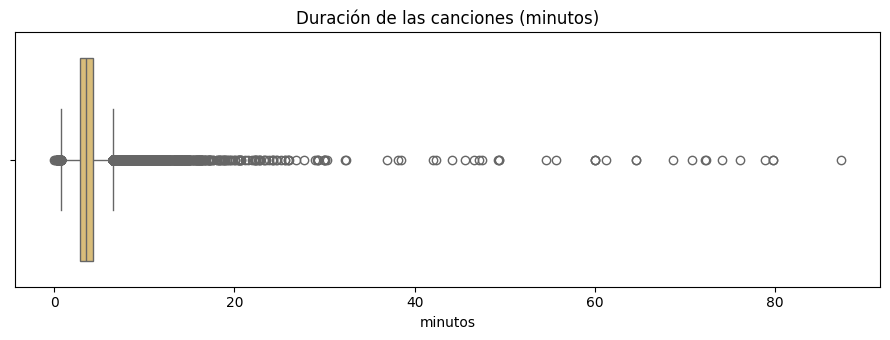

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(x=df["duration_ms"] / 60000, color="#e9c46a", ax=ax)
ax.set_title("Duración de las canciones (minutos)")
ax.set_xlabel("minutos")
plt.tight_layout()
plt.show()

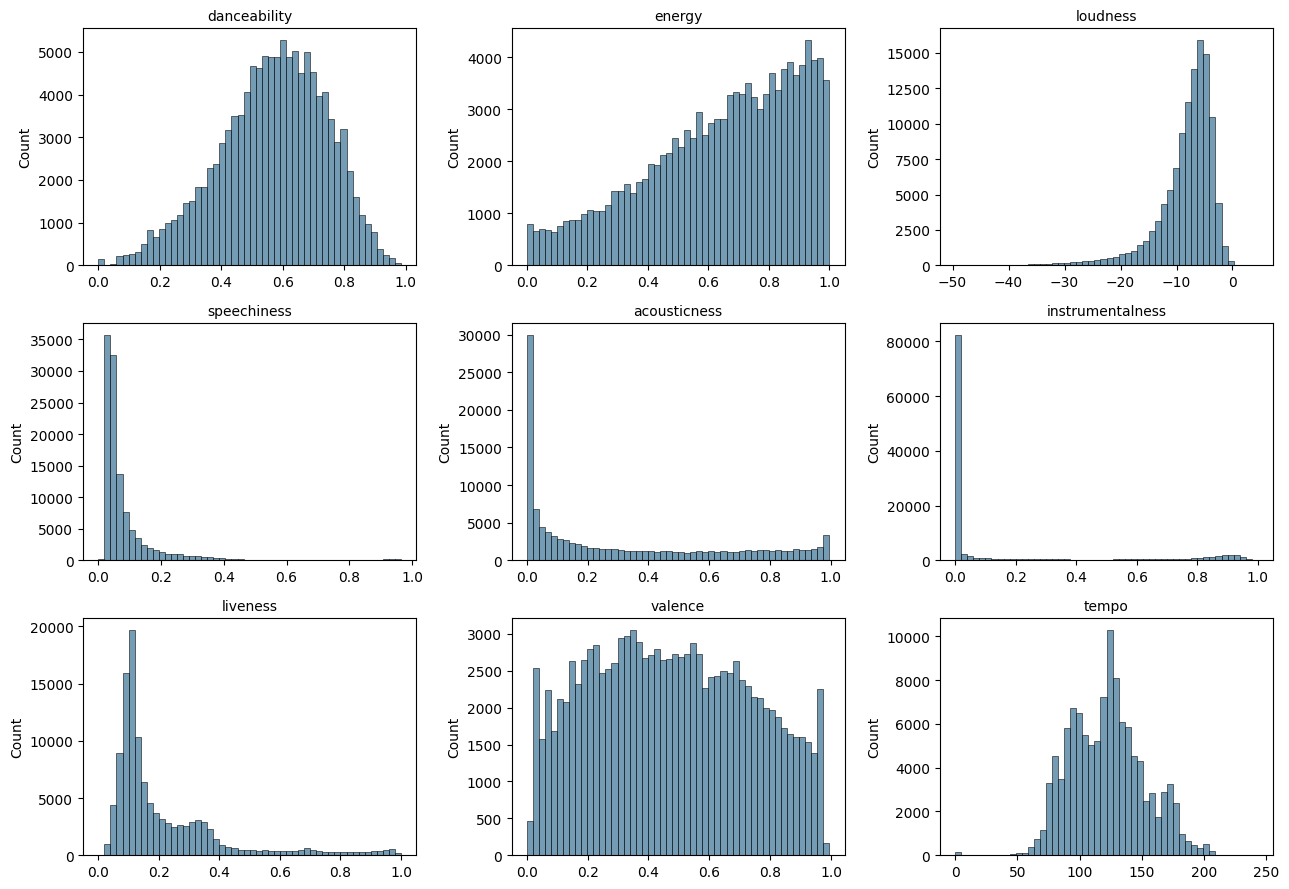

In [25]:
audio = ["danceability", "energy", "loudness", "speechiness",
         "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.flat, audio):
    sns.histplot(df[col], bins=50, ax=ax, color="#457b9d")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Los valores extremos corresponden a repertorio legítimo (música ambiental,
mezclas continuas, grabaciones en vivo) y no a errores de registro. Eliminarlos
sería descartar música válida del catálogo.

Decision: se eliminan únicamente los valores físicamente imposibles
detectados en el punto 3.2. Los extremos se conservan, aplicando transformación
logarítmica a duration_ms en la preparación para que la asimetría no domine
a los modelos sensibles a la escala.

## 4. Análisis exploratorio orientado al negocio

La pregunta que define la viabilidad del proyecto: ¿las características
de audio son capaces de explicar la popularidad de una canción?

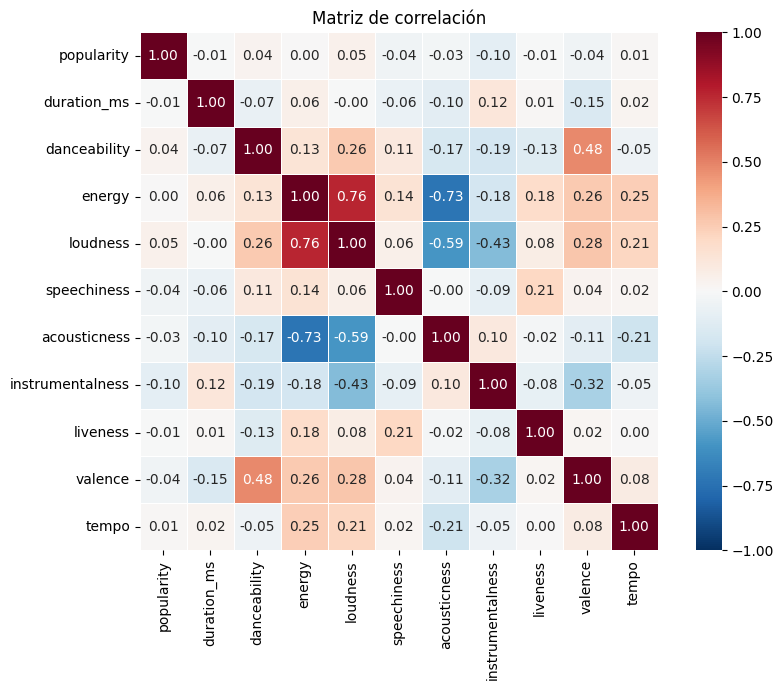

In [26]:
numericas = ["popularity", "duration_ms"] + audio
corr = df[numericas].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

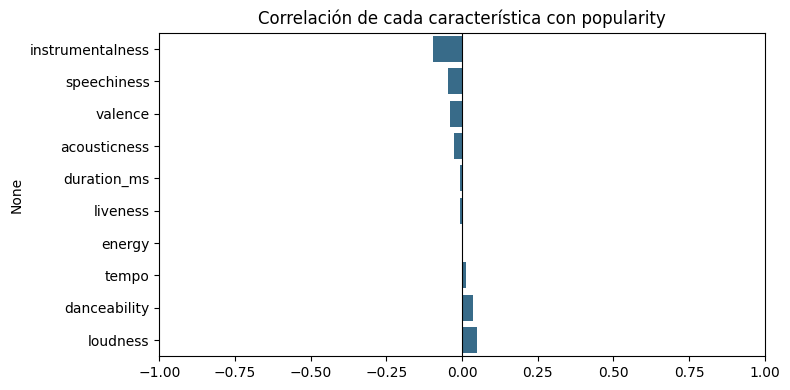

instrumentalness   -0.095
speechiness        -0.045
valence            -0.041
acousticness       -0.025
duration_ms        -0.007
liveness           -0.005
energy              0.001
tempo               0.013
danceability        0.035
loudness            0.050
Name: popularity, dtype: float64


In [27]:
corr_target = corr["popularity"].drop("popularity").sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=corr_target.values, y=corr_target.index, color="#2a6f97", ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_title("Correlación de cada característica con popularity")
plt.tight_layout()
plt.show()

print(corr_target.round(3))

Ninguna característica de audio supera una correlación absoluta de 0,10 con la
popularidad. La mayor es instrumentalness con -0,095. Las propiedades sonoras de
una canción, tomadas individualmente, no explican su popularidad.

lo que significa que la popularidad depende de inclusión en listas editoriales, promoción y reconocimiento previo del artista, ninguno de los cuales está en las columnas de audio.

In [49]:
def eta_cuadrado(datos, grupo, valor):
    media_general = datos[valor].mean()
    g = datos.groupby(grupo)[valor]
    entre = (g.count() * (g.mean() - media_general) ** 2).sum()
    total = ((datos[valor] - media_general) ** 2).sum()
    return entre / total

eta = eta_cuadrado(df, "track_genre", "popularity")
print(f"Varianza explicada por el género:        {eta:.1%}")
print(f"Varianza explicada por el mejor audio:   {corr_target.abs().max()**2:.1%}")

eta_sin_ceros = eta_cuadrado(df[df["popularity"] > 0], "track_genre", "popularity")
print(f"Varianza explicada por el género sin contar datos con popularity 0: {eta_sin_ceros:.1%}")

Varianza explicada por el género:        25.4%
Varianza explicada por el mejor audio:   0.9%
Varianza explicada por el género sin contar datos con popularity 0: 37.9%


/tmp/ipykernel_632/1131096891.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df["track_genre"].isin(extremos.index)],


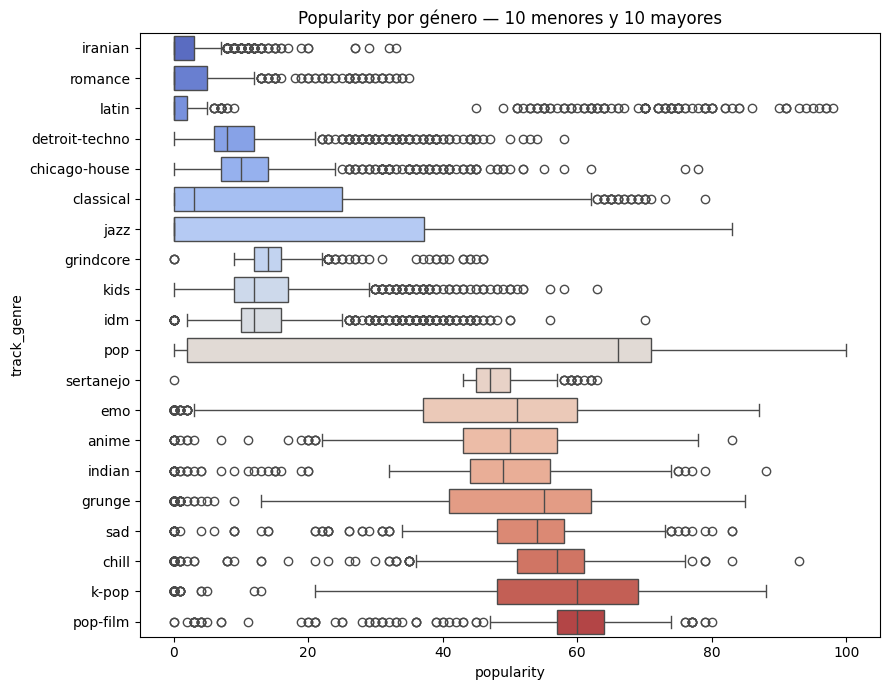

2.2 (iranian) a 59.3 (pop-film)


In [29]:
pop_genero = df.groupby("track_genre")["popularity"].mean().sort_values()
extremos = pd.concat([pop_genero.head(10), pop_genero.tail(10)])

fig, ax = plt.subplots(figsize=(9, 7))
sns.boxplot(data=df[df["track_genre"].isin(extremos.index)],
            y="track_genre", x="popularity", order=extremos.index,
            palette="coolwarm", ax=ax)
ax.set_title("Popularity por género — 10 menores y 10 mayores")
plt.tight_layout()
plt.show()

print(f"{pop_genero.min():.1f} ({pop_genero.idxmin()}) a {pop_genero.max():.1f} ({pop_genero.idxmax()})")

El género explica cerca del 25% de la varianza de la popularidad, frente a menos
del 1% de la mejor característica de audio. La diferencia entre el género de menor promedio (iranian, 2,2) y el mayor (pop-film, 59,3) supera los 57 puntos.

Conclusión que orienta el modelado: el contexto cultural y de catálogo pesa mucho  más que el contenido sonoro. El proyecto debe plantearse como predicción de popularidad relativa dentro del género, no como una fórmula universal del éxito.

## 5. Preparación de datos

Cada transformación responde a un hallazgo documentado anteriormente.

In [30]:
limpio = df.copy()

limpio = limpio.drop(columns=["Unnamed: 0"])
limpio = limpio.dropna(subset=["track_name", "artists", "album_name"])
limpio = limpio[(limpio["duration_ms"] > 0) & (limpio["tempo"] > 0)]
limpio = limpio[limpio["time_signature"].between(3, 7)]
limpio = limpio.drop_duplicates()

print(f"Filas tras limpieza básica: {len(limpio):,}")

Filas tras limpieza básica: 112,419


Da 16.203 multigénero, solo 530 sin empate y 15.673 con empate. La popularidad de una canción casi no cambia entre sus géneros, así que idxmax terminaría eligiendo por orden del archivo, que también es arbitrario.

Antes se tomaba el primer género en orden alfabético, lo que asignaba por la letra y no por un criterio real. Se evaluó elegir el género de mayor popularidad, pero en 15.673 de 16.203 canciones multigénero hay empate, así que esa elección también sería arbitraria. Se adopta el género más específico (el de menos canciones únicas en el catálogo): las etiquetas amplias (pop, rock) describen peor a la canción que las específicas (k-pop, alt-rock). El criterio no usa popularity, por lo que no filtra información del objetivo. Se conserva generos con todas las etiquetas para poder usar un enfoque multi-etiqueta en el modelado.

In [41]:
columnas_first = ["artists", "album_name", "track_name", "explicit",
                  "duration_ms", "key", "mode", "time_signature"] + audio

agregacion = {c: "first" for c in columnas_first}
agregacion["popularity"] = "median"

dedup = limpio.groupby("track_id").agg(agregacion)
dedup["generos"] = limpio.groupby("track_id")["track_genre"].apply(lambda s: ";".join(sorted(set(s))))
dedup["n_generos"] = limpio.groupby("track_id")["track_genre"].nunique()
pares = limpio[["track_id", "track_genre"]].drop_duplicates()
n_canciones_genero = pares.groupby("track_genre")["track_id"].nunique()
pares["n_canciones_genero"] = pares["track_genre"].map(n_canciones_genero)
principal = (pares.sort_values(["track_id", "n_canciones_genero", "track_genre"])
                  .drop_duplicates("track_id")
                  .set_index("track_id")["track_genre"])
dedup["genero_principal"] = dedup.index.map(principal)
dedup["popularity"] = dedup["popularity"].round().astype(int)
dedup = dedup.reset_index()

print(f"Deduplicación: {len(limpio):,} -> {len(dedup):,}")

Deduplicación: 112,419 -> 88,732


Se consolidaron 23.687 filas que correspondían a la misma canción repetida en varios géneros.

In [32]:
modelable = dedup[dedup["popularity"] > 0].copy()
excluidas = dedup[dedup["popularity"] == 0].copy()

print(f"Modelable: {len(modelable):,}")
print(f"Excluidas: {len(excluidas):,}")
print()
print(excluidas["genero_principal"].value_counts().head(8))

Modelable: 79,419
Excluidas: 9,313

genero_principal
iranian      622
country      552
romance      540
dance        452
latin        430
jazz         399
alt-rock     349
classical    327
Name: count, dtype: int64


In [45]:
modelable["duration_min"] = modelable["duration_ms"] / 60000
modelable["duration_log"] = np.log1p(modelable["duration_ms"])
modelable["es_instrumental"] = (modelable["instrumentalness"] > 0.5).astype(int)
modelable["es_vivo"] = (modelable["liveness"] > 0.80).astype(int)
modelable["explicit"] = modelable["explicit"].astype(int)
modelable["id_contenido"] = modelable.groupby(
    ["track_name", "artists", "duration_ms"]).ngroup()

modelable.to_csv(DATA / "spotify_modelable.csv", index=False)
excluidas.to_csv(DATA / "spotify_excluidas_pop0.csv", index=False)

print(f"Original: {len(df):,} -> Modelable: {len(modelable):,}")

Original: 114,000 -> Modelable: 79,419


Se logró obtener un total final de 79,419 filas de datos para el modelo.

### 6. Cálculo de la línea base para los KPIs

In [39]:
y = modelable["popularity"]

mae_global = (y - y.mean()).abs().mean()
media_genero = modelable.groupby("genero_principal")["popularity"].transform("mean")
mae_genero = (y - media_genero).abs().mean()

print(f"MAE prediciendo la media global:     {mae_global:.2f}")
print(f"MAE prediciendo la media del género: {mae_genero:.2f}")
print(f"Mejora: {(1 - mae_genero / mae_global) * 100:.1f}%")

MAE prediciendo la media global:     15.15
MAE prediciendo la media del género: 9.75
Mejora: 35.6%


In [44]:
modelable["g_alfabetico"] = modelable["generos"].str.split(";").str[0]
mae_alf = (y - modelable.groupby("g_alfabetico")["popularity"].transform("mean")).abs().mean()
print(f"\nMAE con criterio alfabético (antes): {mae_alf:.2f}")
print(f"MAE con género más específico (ahora): {mae_genero:.2f}")


MAE con criterio alfabético (antes): 9.75
MAE con género más específico (ahora): 9.75


## 7. Sesgos, ética y privacidad

### 7.1 Sesgos identificados en los datos

**Sesgo de selección por género.** El dataset contiene exactamente 1.000 canciones
por género, un balance artificial que no refleja la composición real del catálogo
de Spotify. Los géneros mayoritarios quedan subrepresentados y los minoritarios
sobrerrepresentados.

**Sesgo de disponibilidad del dato.** La ausencia de popularidad se concentra en
géneros específicos (jazz 68%, iraní 66%, romance 64%). Al excluir esos registros,
el modelo queda entrenado sobre un repertorio sesgado hacia la música de mercados
anglosajones y de consumo masivo.

**Sesgo de retroalimentación.** popularity no es una medida neutral de calidad
musical: refleja lo que Spotify ya promovió. Las canciones incluidas en listas
editoriales reciben más escuchas, lo que aumenta su popularidad, lo que justifica
incluirlas en más listas. Un modelo entrenado con esta variable aprende a
reproducir las decisiones editoriales pasadas de la plataforma, no a detectar
potencial musical.

**Consecuencia para el negocio.** Si el modelo se usa para priorizar promoción,
tenderá a recomendar más de lo mismo y a invisibilizar repertorios que hoy ya
están poco medidos. El cuarto KPI (equidad entre géneros) existe para detectar
ese efecto.

### 7.2 Privacidad y protección de datos

El dataset no contiene datos personales de usuarios: no hay identificadores de
oyentes, historiales de escucha ni información demográfica. La popularidad viene
agregada, por lo que no es posible reconstruir el comportamiento de ninguna
persona a partir de estos datos.

Sí contiene datos de personas identificables: los nombres de artistas son datos
personales de individuos reales. Su tratamiento se limita a fines académicos y de
análisis agregado. En este proyecto no se elabora ningún perfil ni ranking
individual de artistas, y los nombres no se utilizan como variable predictora.

Bajo la Ley 21.719 de protección de datos personales, un nombre
artístico asociado a métricas de desempeño constituye dato personal cuando permite
identificar a la persona. Por eso el uso comercial de estos resultados requeriría
verificar los términos de la API de Spotify, que restringen el uso de sus datos
con fines de entrenamiento de modelos.

### 7.3 Limitaciones éticas del uso del modelo

- El modelo no debe usarse para decidir la contratación o desvinculación de
  artistas: predice una métrica de plataforma, no el valor de una obra.
- Los resultados valen para el momento de la extracción de los datos. No hay marca
  temporal en el dataset, por lo que no se puede verificar su vigencia.
- La popularidad es una métrica propietaria cuyo cálculo Spotify no publica. El
  proyecto predice un número opaco, y esa opacidad debe declararse ante cualquier
  usuario del modelo.

## 8. Conclusiones

1. El dataset aparenta estar limpio porque casi no tiene nulos, y ese es su
   principal riesgo: los problemas graves están en duplicación e inconsistencia.
2. La duplicación multigénero es el hallazgo más serio: sin resolverla, cualquier
   validación produce métricas infladas por fuga de datos.
3. El cero en popularity es dato faltante, no impopularidad. Su concentración por
   género convierte la limpieza en una decisión con consecuencias éticas.
4. Las características de audio no explican la popularidad (|r| < 0,10) mientras
   el género explica el 25%.
5. Limitación: el dataset no tiene marca temporal y popularity es una métrica
   propietaria y cambiante. Los resultados valen para el momento de la extracción.

Trazabilidad: 114.000 filas originales -> 79.419 canciones modelables (-30,3%).